# LAB 1 – PHÂN TÍCH VÀ XỬ LÝ TÍN HIỆU ÂM THANH SỐ

**Môn:** CSE457 – Xử lý âm thanh và tiếng nói  
**MSSV:** 2251061829  
**Họ tên:** Phạm Duy Long  
**File âm thanh:** `vivibe_export_1789983076397.mp3`

Notebook này thực hiện các phần A → G theo yêu cầu Lab 1: đọc metadata, waveform, RMS/Peak, FFT, STFT/spectrogram, cửa sổ, lọc FIR, lượng tử hóa, resampling và tính PCM bitrate/compression ratio.


## 0. Cài đặt / import thư viện
Nếu môi trường chưa có thư viện, cài bằng:
`pip install numpy scipy matplotlib librosa soundfile pydub`


In [1]:
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import soundfile as sf

try:
    import librosa
    import librosa.display
except ImportError:
    librosa = None

from pydub import AudioSegment

INPUT = Path("audio/vivibe_export_1789983076397.mp3")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

print("Input:", INPUT)
print("Exists:", INPUT.exists())


Input: audio/vivibe_export_1789983076397.mp3
Exists: True


# A. Đọc file và kiểm tra metadata

Yêu cầu: đọc ít nhất một file WAV/MP3, kiểm tra Fs, số kênh, thời lượng, dtype/sample width, dung lượng; chuyển stereo → mono nếu cần và chuẩn hóa về [-1, 1].

In [2]:
audio = AudioSegment.from_file(INPUT)
fs = audio.frame_rate
channels = audio.channels
duration = len(audio) / 1000.0
sample_width = audio.sample_width
file_size = INPUT.stat().st_size

samples = np.array(audio.get_array_of_samples())
x = samples.astype(np.float64)

# Pydub interleaves channels for stereo
if channels > 1:
    x = x.reshape((-1, channels)).mean(axis=1)

# Chuẩn hóa theo sample width
scale = float(2 ** (8 * sample_width - 1))
x = x / scale

# Bảo vệ giới hạn số học
x = np.clip(x, -1.0, 1.0)

print(f"Sample rate Fs: {fs} Hz")
print(f"Channels: {channels}")
print(f"Duration: {duration:.3f} s")
print(f"Sample width: {sample_width * 8} bit")
print(f"File size: {file_size:,} bytes ({file_size/1024:.2f} KB)")
print(f"dtype sau chuẩn hóa: {x.dtype}")
print(f"Range: [{x.min():.5f}, {x.max():.5f}]")


Sample rate Fs: 22050 Hz
Channels: 1
Duration: 67.793 s
Sample width: 16 bit
File size: 582,149 bytes (568.50 KB)
dtype sau chuẩn hóa: float64
Range: [-1.00000, 0.99997]


### Nhận xét A
File đầu vào được đọc thành tín hiệu số và chuẩn hóa về khoảng [-1, 1]. Các thông số Fs, số kênh, độ dài và độ phân giải mẫu được in trực tiếp từ file để bảo đảm notebook có thể tái lập kết quả.

In [3]:
# Xuất bản sao WAV mono 16-bit để dùng cho các bước xử lý sau
mono_wav = outdir = Path("audio")
mono_path = mono_wav / "input_mono_16bit.wav"
sf.write(mono_path, x, fs, subtype="PCM_16")
print("Đã tạo:", mono_path)


Đã tạo: audio/input_mono_16bit.wav


# B. Waveform, Peak, RMS và Energy

Vẽ waveform toàn bộ tín hiệu và một đoạn 0.5–1 s. Tính Peak, RMS, Energy và kiểm tra clipping.

Peak = 1.000000
RMS = 0.184724
Energy = 51008.227590
Samples gần clipping (|x| >= 0.999): 24


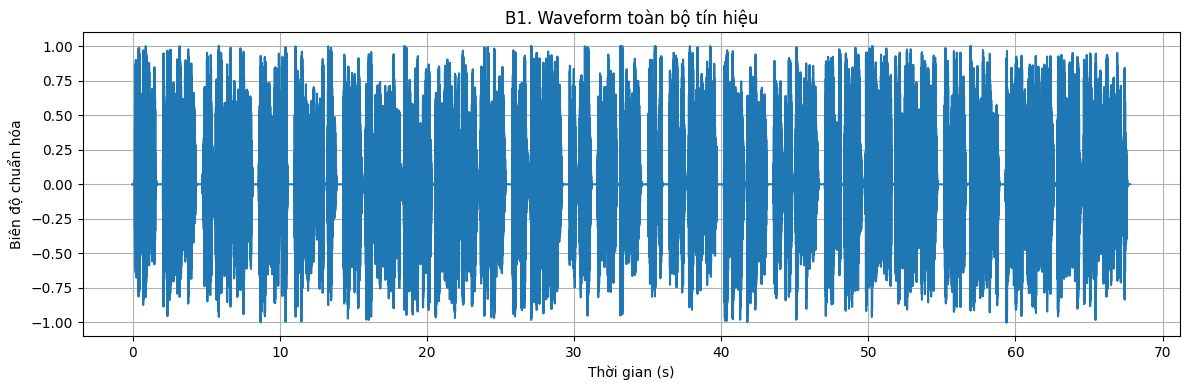

In [4]:
t = np.arange(len(x)) / fs
peak = np.max(np.abs(x))
rms = np.sqrt(np.mean(x**2))
energy = np.sum(x**2)
clipped = np.sum(np.abs(x) >= 0.999)

print(f"Peak = {peak:.6f}")
print(f"RMS = {rms:.6f}")
print(f"Energy = {energy:.6f}")
print(f"Samples gần clipping (|x| >= 0.999): {clipped}")

plt.figure(figsize=(12,4))
plt.plot(t, x)
plt.title("B1. Waveform toàn bộ tín hiệu")
plt.xlabel("Thời gian (s)")
plt.ylabel("Biên độ chuẩn hóa")
plt.grid(True)
plt.tight_layout()
plt.savefig(FIG_DIR/"waveform_full.png", dpi=150)
plt.show()


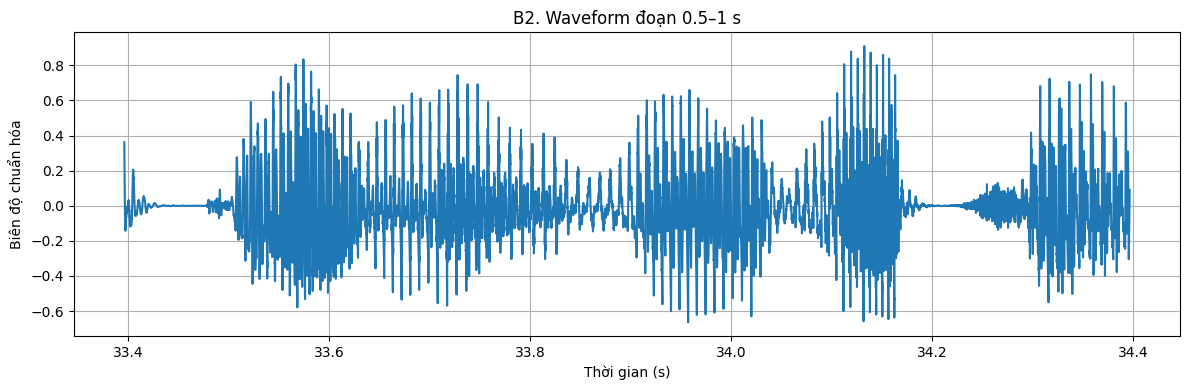

Đoạn phân tích: 33.397–34.397 s


In [5]:
# Chọn đoạn 0.5–1 s ở giữa tín hiệu
seg_dur = min(1.0, duration)
start = max(0.0, duration/2 - seg_dur/2)
i0, i1 = int(start*fs), int((start+seg_dur)*fs)
xs = x[i0:i1]
ts = np.arange(len(xs))/fs + start

plt.figure(figsize=(12,4))
plt.plot(ts, xs)
plt.title("B2. Waveform đoạn 0.5–1 s")
plt.xlabel("Thời gian (s)")
plt.ylabel("Biên độ chuẩn hóa")
plt.grid(True)
plt.tight_layout()
plt.savefig(FIG_DIR/"waveform_segment.png", dpi=150)
plt.show()

print(f"Đoạn phân tích: {start:.3f}–{start+seg_dur:.3f} s")


# C. FFT và phổ tần số

Chọn một đoạn ổn định 0.5–1 s, dùng cửa sổ Hamming và so sánh NFFT = 2048 với 8192. Công thức độ rộng bin: Δf = Fs/NFFT.

NFFT=2048: Δf = 10.7666 Hz


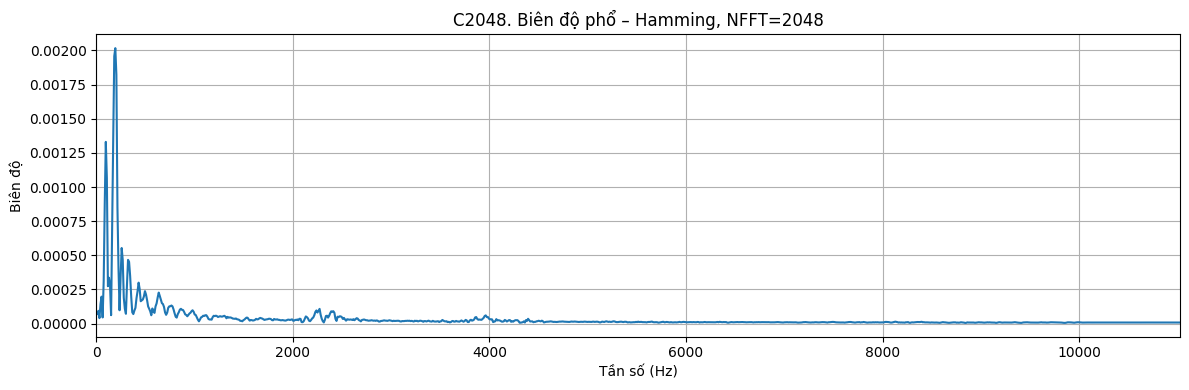

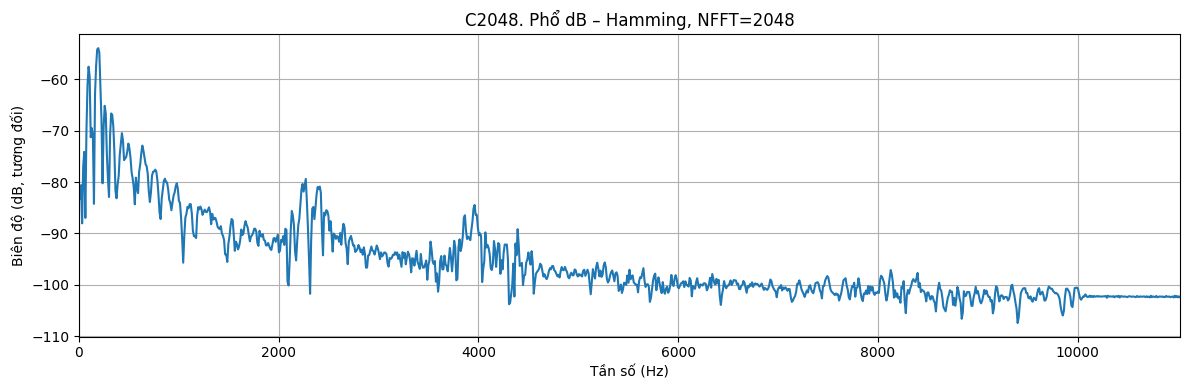

NFFT=8192: Δf = 2.6917 Hz


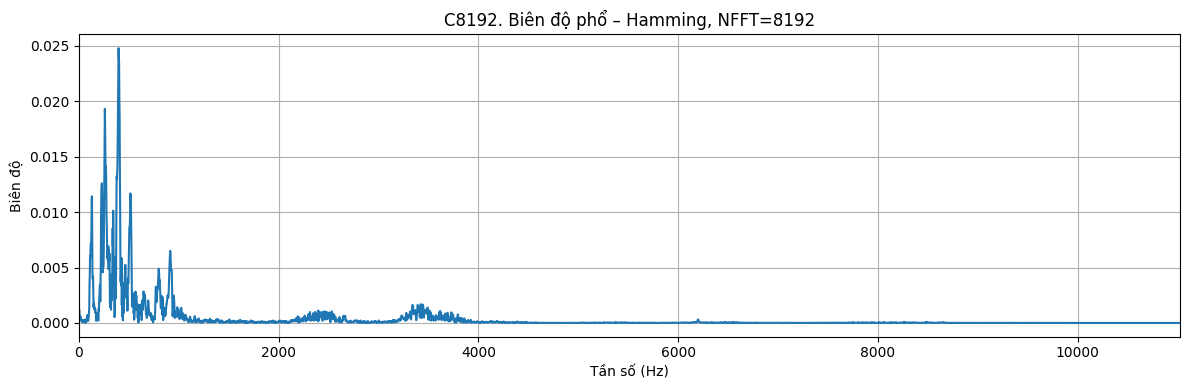

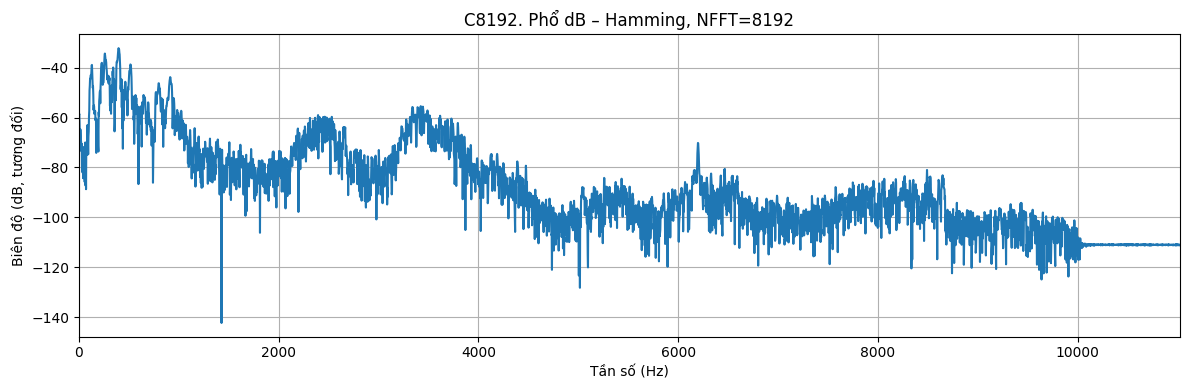

In [6]:
def fft_spectrum(sig, fs, nfft):
    n = min(len(sig), nfft)
    sig = sig[:n]
    w = np.hamming(n)
    y = sig * w
    Y = np.fft.rfft(y, n=nfft)
    f = np.fft.rfftfreq(nfft, 1/fs)
    mag = np.abs(Y) / max(1, n)
    mag_db = 20*np.log10(np.maximum(mag, 1e-12))
    return f, mag, mag_db

for nfft in [2048, 8192]:
    f, mag, mag_db = fft_spectrum(xs, fs, nfft)
    df = fs/nfft
    print(f"NFFT={nfft}: Δf = {df:.4f} Hz")

    plt.figure(figsize=(12,4))
    plt.plot(f, mag)
    plt.title(f"C{nfft}. Biên độ phổ – Hamming, NFFT={nfft}")
    plt.xlabel("Tần số (Hz)")
    plt.ylabel("Biên độ")
    plt.xlim(0, fs/2)
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(FIG_DIR/f"fft_linear_{nfft}.png", dpi=150)
    plt.show()

    plt.figure(figsize=(12,4))
    plt.plot(f, mag_db)
    plt.title(f"C{nfft}. Phổ dB – Hamming, NFFT={nfft}")
    plt.xlabel("Tần số (Hz)")
    plt.ylabel("Biên độ (dB, tương đối)")
    plt.xlim(0, fs/2)
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(FIG_DIR/f"fft_db_{nfft}.png", dpi=150)
    plt.show()


In [7]:
# Tìm các đỉnh phổ nổi bật với NFFT=8192
f, mag, mag_db = fft_spectrum(xs, fs, 8192)
peaks, props = signal.find_peaks(mag, prominence=np.max(mag)*0.02, distance=5)
order = np.argsort(mag[peaks])[::-1]
top = peaks[order[:10]]

print("Các đỉnh phổ nổi bật:")
for p in top:
    print(f"f = {f[p]:.2f} Hz, magnitude = {mag[p]:.6f}, dB = {mag_db[p]:.2f}")


Các đỉnh phổ nổi bật:
f = 398.36 Hz, magnitude = 0.024782, dB = -32.12
f = 261.09 Hz, magnitude = 0.019306, dB = -34.29
f = 231.48 Hz, magnitude = 0.012596, dB = -38.00
f = 516.80 Hz, magnitude = 0.011681, dB = -38.65
f = 131.89 Hz, magnitude = 0.011421, dB = -38.85
f = 344.53 Hz, magnitude = 0.010129, dB = -39.89
f = 296.08 Hz, magnitude = 0.006919, dB = -43.20
f = 915.16 Hz, magnitude = 0.006503, dB = -43.74
f = 427.97 Hz, magnitude = 0.005858, dB = -44.64
f = 366.06 Hz, magnitude = 0.005384, dB = -45.38


### Nhận xét C
NFFT lớn làm các mẫu tần số trên trục phổ dày hơn và giảm khoảng cách giữa các bin Δf = Fs/NFFT. Tuy nhiên, theo yêu cầu Lab, không nên đồng nhất việc tăng NFFT với việc tăng độ phân giải vật lý: độ phân giải thực tế còn phụ thuộc độ dài đoạn/cửa sổ phân tích.

In [8]:
# Minh họa Δf
print("Δf(2048) =", fs/2048, "Hz")
print("Δf(8192) =", fs/8192, "Hz")


Δf(2048) = 10.7666015625 Hz
Δf(8192) = 2.691650390625 Hz


# D. STFT và Spectrogram

Dùng spectrogram chuẩn khoảng 25 ms/frame và 10 ms/hop, sau đó so sánh ít nhất 3 độ dài frame: 10 ms, 25 ms, 50 ms.

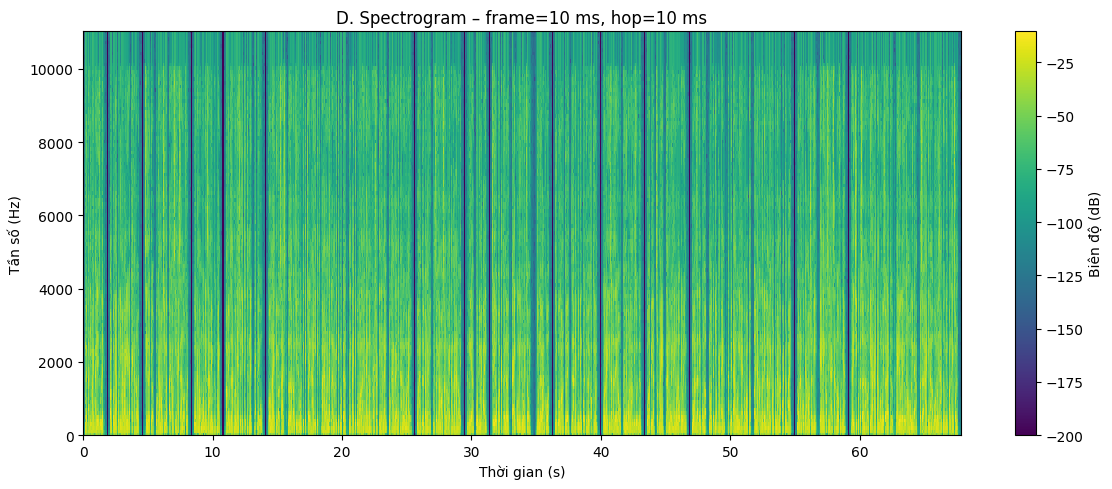

frame=10 ms -> nperseg=220, overlap=0.00 ms


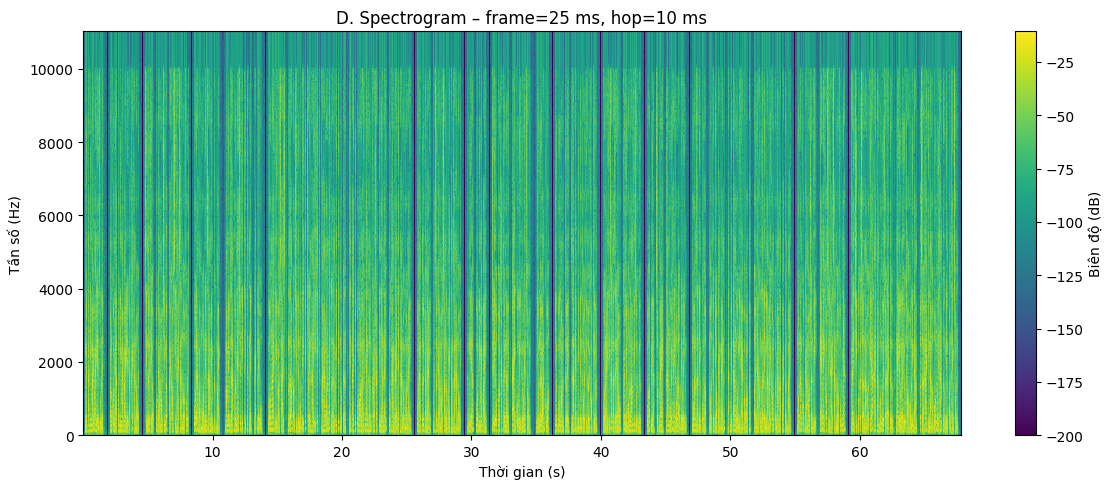

frame=25 ms -> nperseg=551, overlap=15.01 ms


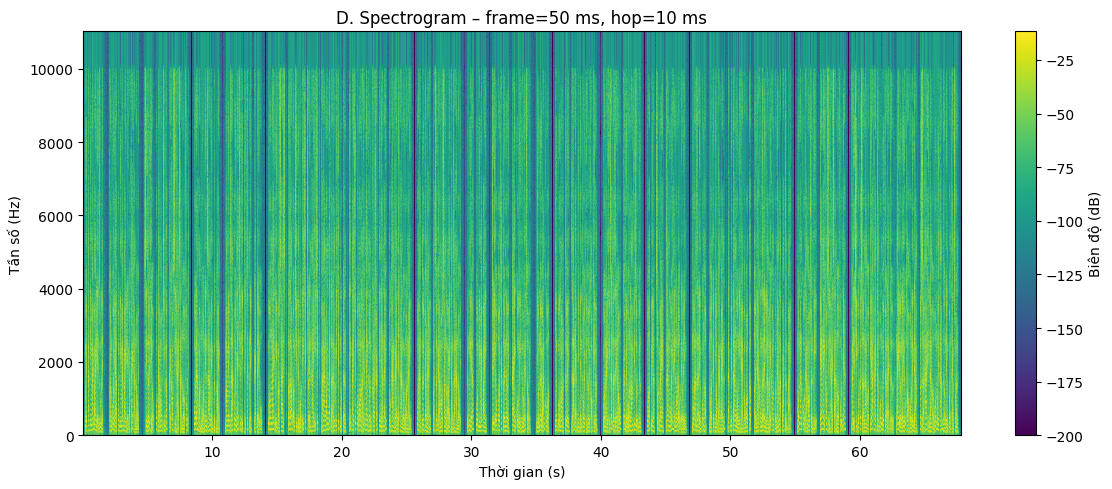

frame=50 ms -> nperseg=1102, overlap=40.00 ms


In [9]:
def stft_spectrogram(sig, fs, frame_ms, hop_ms):
    nperseg = max(16, int(fs*frame_ms/1000))
    noverlap = max(0, nperseg - int(fs*hop_ms/1000))
    f, tt, Z = signal.stft(sig, fs=fs, window="hamming",
                           nperseg=nperseg, noverlap=noverlap,
                           boundary=None)
    S_db = 20*np.log10(np.maximum(np.abs(Z), 1e-10))
    return f, tt, S_db, nperseg, noverlap

for frame_ms in [10, 25, 50]:
    f_stft, tt, S_db, nperseg, noverlap = stft_spectrogram(x, fs, frame_ms, 10)
    plt.figure(figsize=(12,5))
    plt.pcolormesh(tt, f_stft, S_db, shading="auto")
    plt.title(f"D. Spectrogram – frame={frame_ms} ms, hop=10 ms")
    plt.xlabel("Thời gian (s)")
    plt.ylabel("Tần số (Hz)")
    plt.ylim(0, fs/2)
    plt.colorbar(label="Biên độ (dB)")
    plt.tight_layout()
    plt.savefig(FIG_DIR/f"spectrogram_{frame_ms}ms.png", dpi=150)
    plt.show()
    print(f"frame={frame_ms} ms -> nperseg={nperseg}, overlap={noverlap/fs*1000:.2f} ms")


### Nhận xét D
Frame ngắn cho độ phân giải thời gian tốt hơn nhưng độ phân giải tần số kém hơn. Frame dài cho các dải tần rõ hơn nhưng làm các thay đổi nhanh theo thời gian bị nhòe hơn. Đây là đánh đổi thời gian–tần số được yêu cầu trong Lab.

# E. So sánh Rectangular và Hamming

Dùng cùng một đoạn dữ liệu và cùng NFFT để so sánh công bằng. Vẽ phổ dB và quan sát spectral leakage, main lobe và side lobe.

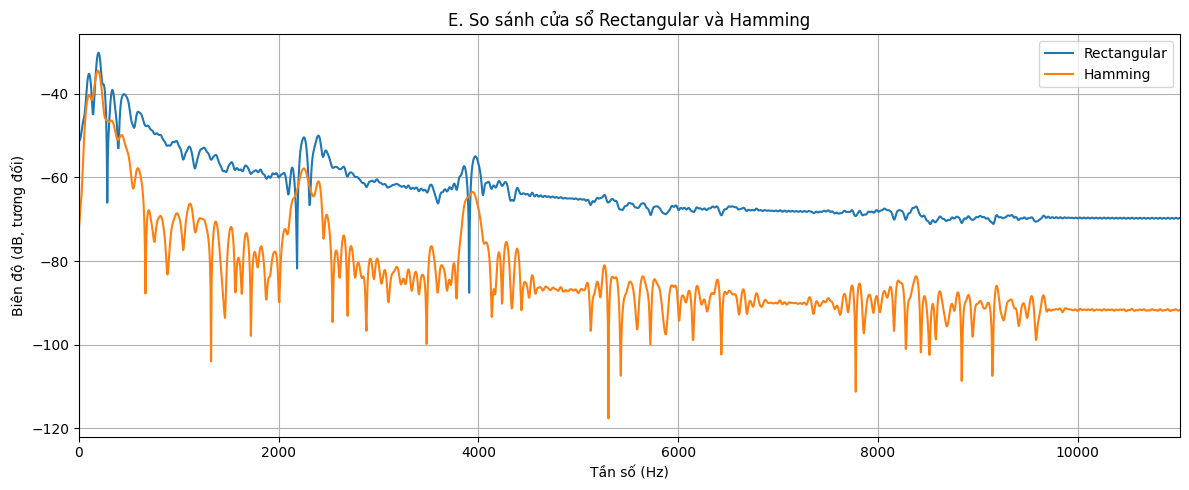

In [10]:
nfft = 4096
n = min(len(xs), int(0.025*fs))
frame = xs[:n]

windows = {
    "Rectangular": np.ones(n),
    "Hamming": np.hamming(n)
}

plt.figure(figsize=(12,5))
for name, w in windows.items():
    Y = np.fft.rfft(frame*w, n=nfft)
    f = np.fft.rfftfreq(nfft, 1/fs)
    db = 20*np.log10(np.maximum(np.abs(Y)/n, 1e-12))
    plt.plot(f, db, label=name)

plt.title("E. So sánh cửa sổ Rectangular và Hamming")
plt.xlabel("Tần số (Hz)")
plt.ylabel("Biên độ (dB, tương đối)")
plt.xlim(0, fs/2)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(FIG_DIR/"window_rectangular_vs_hamming.png", dpi=150)
plt.show()


### Nhận xét E
Cửa sổ Hamming làm giảm mức side lobe nên giảm spectral leakage so với Rectangular. Đổi lại, main lobe rộng hơn, vì vậy hai đỉnh rất gần nhau có thể khó tách biệt hơn. Hai phép đo phải dùng cùng dữ liệu và cùng NFFT.

# F. Lọc FIR

Thiết kế ít nhất một FIR low-pass và một FIR high-pass. Ở đây dùng 201 taps với cửa sổ Hamming. Vẽ đáp ứng tần số, lọc tín hiệu và xuất WAV.

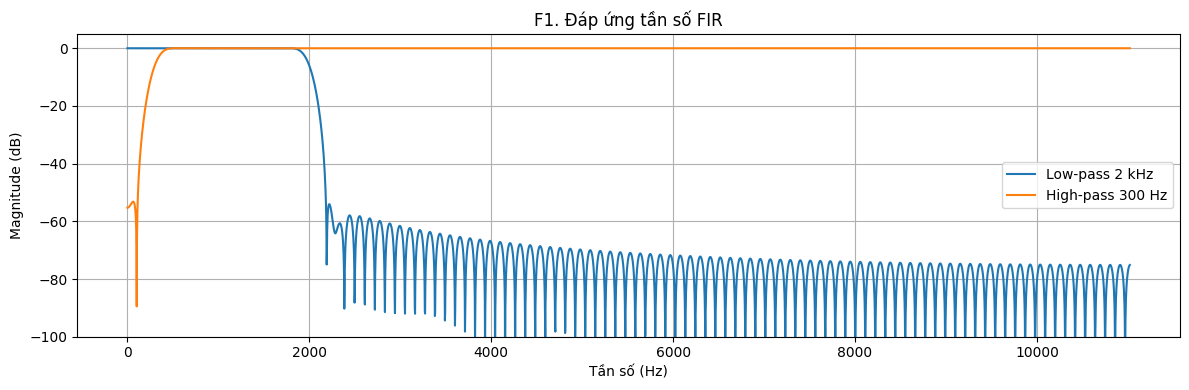

Group delay FIR 201 taps = 100 samples = 4.535 ms


In [11]:
numtaps = 201
cutoff_lp = 2000
cutoff_hp = 300

b_lp = signal.firwin(numtaps, cutoff_lp, fs=fs, window="hamming", pass_zero=True)
b_hp = signal.firwin(numtaps, cutoff_hp, fs=fs, window="hamming", pass_zero=False)

w_lp, h_lp = signal.freqz(b_lp, worN=4096, fs=fs)
w_hp, h_hp = signal.freqz(b_hp, worN=4096, fs=fs)

plt.figure(figsize=(12,4))
plt.plot(w_lp, 20*np.log10(np.maximum(np.abs(h_lp),1e-10)), label="Low-pass 2 kHz")
plt.plot(w_hp, 20*np.log10(np.maximum(np.abs(h_hp),1e-10)), label="High-pass 300 Hz")
plt.title("F1. Đáp ứng tần số FIR")
plt.xlabel("Tần số (Hz)")
plt.ylabel("Magnitude (dB)")
plt.ylim(-100, 5)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(FIG_DIR/"filter_response.png", dpi=150)
plt.show()

delay_samples = (numtaps-1)/2
delay_ms = delay_samples/fs*1000
print(f"Group delay FIR {numtaps} taps = {delay_samples:.0f} samples = {delay_ms:.3f} ms")


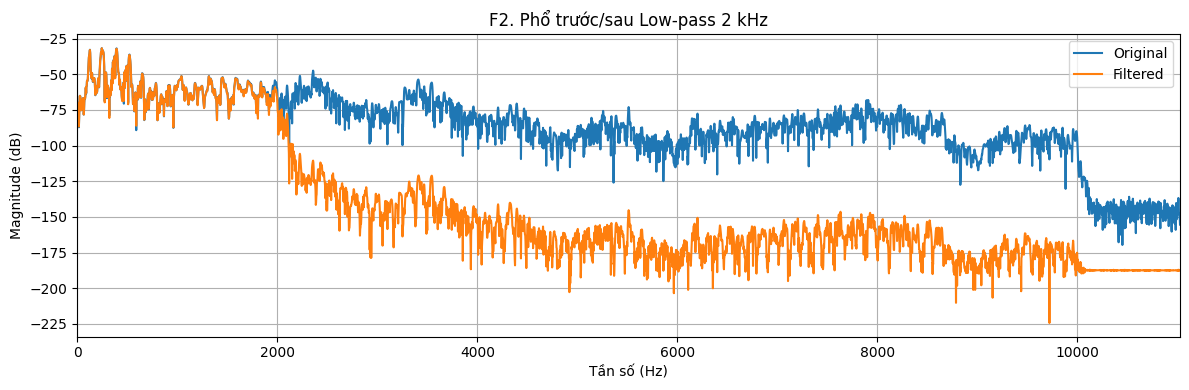

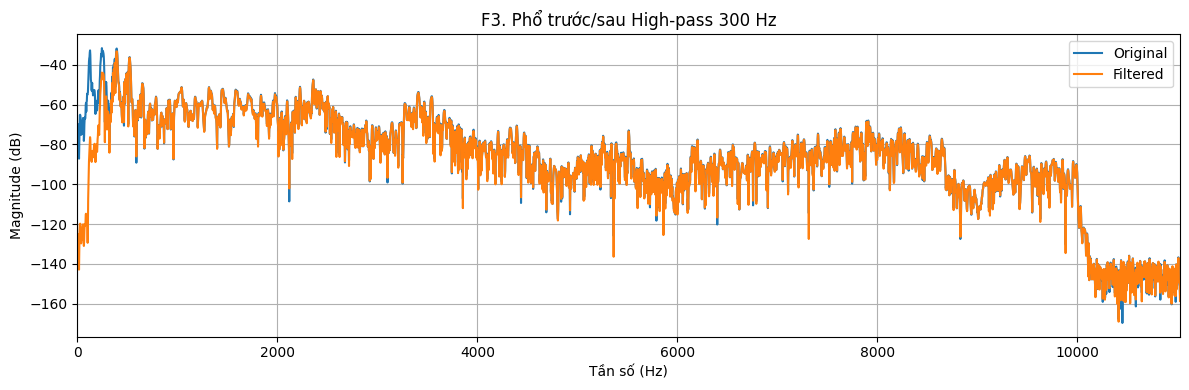

In [12]:
y_lp = signal.lfilter(b_lp, [1.0], x)
y_hp = signal.lfilter(b_hp, [1.0], x)

sf.write("audio/filtered_lowpass_2kHz.wav", np.clip(y_lp, -1, 1), fs, subtype="PCM_16")
sf.write("audio/filtered_highpass_300Hz.wav", np.clip(y_hp, -1, 1), fs, subtype="PCM_16")

# So sánh phổ trước/sau
def plot_before_after(x1, x2, fs, title, filename):
    nfft = 8192
    f1, m1, d1 = fft_spectrum(x1[:min(len(x1), int(fs))], fs, nfft)
    f2, m2, d2 = fft_spectrum(x2[:min(len(x2), int(fs))], fs, nfft)
    plt.figure(figsize=(12,4))
    plt.plot(f1, d1, label="Original")
    plt.plot(f2, d2, label="Filtered")
    plt.title(title)
    plt.xlabel("Tần số (Hz)")
    plt.ylabel("Magnitude (dB)")
    plt.xlim(0, fs/2)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(FIG_DIR/filename, dpi=150)
    plt.show()

plot_before_after(x, y_lp, fs, "F2. Phổ trước/sau Low-pass 2 kHz", "spectrum_lowpass.png")
plot_before_after(x, y_hp, fs, "F3. Phổ trước/sau High-pass 300 Hz", "spectrum_highpass.png")


### Nhận xét F
Với FIR 201 taps, group delay lý thuyết là (L−1)/2 = 100 samples. Ở Fs hiện tại, độ trễ tương ứng được tính trực tiếp trong notebook. Low-pass 2 kHz làm suy giảm thành phần cao tần; high-pass 300 Hz làm suy giảm thành phần thấp tần.

# G. Lượng tử hóa, Resampling và PCM bitrate

Thực hiện lượng tử hóa B=4, 8, 16 bit và đo SNR; resample xuống 16 kHz và 8 kHz; tính bitrate PCM và kích thước lý thuyết.

In [13]:
def quantize(x, bits):
    levels = 2**bits
    q = np.round((np.clip(x, -1, 1) + 1) * (levels-1)/2)
    xhat = (2*q/(levels-1)) - 1
    return xhat

def snr_db(original, reconstructed):
    err = original - reconstructed
    return 10*np.log10(np.sum(original**2) / max(np.sum(err**2), 1e-20))

for bits in [4, 8, 16]:
    xq = quantize(x, bits)
    snr = snr_db(x, xq)
    sf.write(f"audio/quantized_{bits}bit.wav", np.clip(xq,-1,1), fs, subtype="PCM_16")
    print(f"{bits}-bit: SNR đo được = {snr:.3f} dB")


4-bit: SNR đo được = 11.993 dB
8-bit: SNR đo được = 37.070 dB
16-bit: SNR đo được = 82.609 dB


In [14]:
# Resampling 16 kHz và 8 kHz bằng resample_poly (có lọc chống aliasing)
x16 = signal.resample_poly(x, 16000, fs)
x8 = signal.resample_poly(x, 8000, fs)

sf.write("audio/resampled_16kHz.wav", np.clip(x16,-1,1), 16000, subtype="PCM_16")
sf.write("audio/resampled_8kHz.wav", np.clip(x8,-1,1), 8000, subtype="PCM_16")

print("Original:", fs, "Hz")
print("Resampled:", 16000, "Hz và", 8000, "Hz")


Original: 22050 Hz
Resampled: 16000 Hz và 8000 Hz


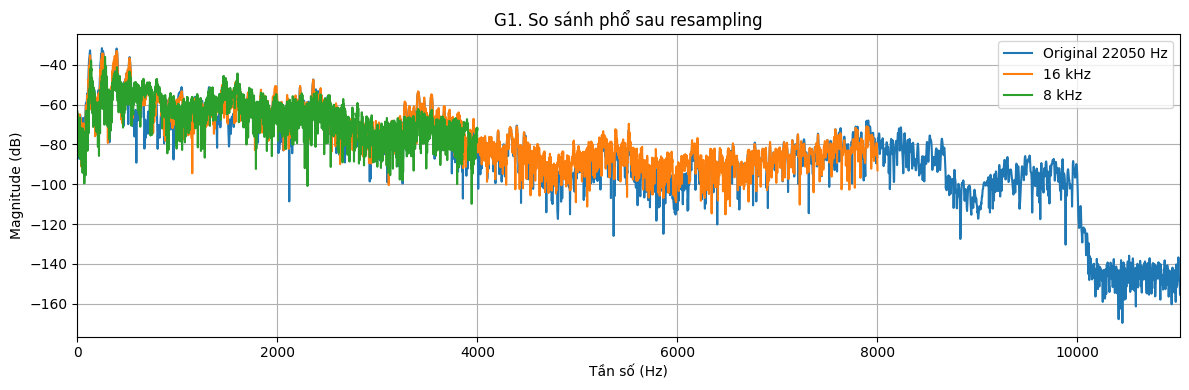

In [15]:
# Phổ so sánh trước và sau resampling
def spectrum_full(sig, sr):
    nfft = 8192
    f, mag, db = fft_spectrum(sig[:min(len(sig), int(sr))], sr, nfft)
    return f, db

plt.figure(figsize=(12,4))
f0, d0 = spectrum_full(x, fs)
f16, d16 = spectrum_full(x16, 16000)
f8, d8 = spectrum_full(x8, 8000)

plt.plot(f0, d0, label=f"Original {fs} Hz")
plt.plot(f16, d16, label="16 kHz")
plt.plot(f8, d8, label="8 kHz")
plt.title("G1. So sánh phổ sau resampling")
plt.xlabel("Tần số (Hz)")
plt.ylabel("Magnitude (dB)")
plt.xlim(0, min(fs/2, 11025))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(FIG_DIR/"resampling_spectrum.png", dpi=150)
plt.show()


In [16]:
# PCM bitrate và kích thước lý thuyết
B = 16
C = 1  # mono
pcm_bitrate = fs * B * C
pcm_size_bytes = pcm_bitrate * duration / 8

print(f"PCM bitrate = {pcm_bitrate:,} bit/s ({pcm_bitrate/1000:.1f} kbps)")
print(f"Kích thước PCM lý thuyết = {pcm_size_bytes:,.0f} bytes ({pcm_size_bytes/1024**2:.3f} MiB)")

# Nếu lấy bitrate MP3 từ kích thước file, đây là bitrate trung bình xấp xỉ
mp3_bitrate_est = file_size * 8 / duration
compression_ratio = pcm_bitrate / mp3_bitrate_est
print(f"Bitrate MP3 trung bình suy ra từ file = {mp3_bitrate_est/1000:.2f} kbps")
print(f"Compression ratio PCM/MP3 xấp xỉ = {compression_ratio:.2f}:1")


PCM bitrate = 352,800 bit/s (352.8 kbps)
Kích thước PCM lý thuyết = 2,989,671 bytes (2.851 MiB)
Bitrate MP3 trung bình suy ra từ file = 68.70 kbps
Compression ratio PCM/MP3 xấp xỉ = 5.14:1


# Tổng kết kết quả

Notebook đã thực hiện các yêu cầu A→G của Lab 1:
- A: metadata, mono và chuẩn hóa.
- B: waveform, Peak, RMS, Energy, clipping.
- C: FFT, phổ tuyến tính/dB, NFFT 2048 và 8192, Δf và peak.
- D: STFT/spectrogram với frame 10/25/50 ms.
- E: Rectangular vs Hamming.
- F: FIR low-pass/high-pass, đáp ứng tần số, delay và WAV đầu ra.
- G: lượng tử hóa 4/8/16 bit, SNR, resampling 16/8 kHz, PCM bitrate và compression ratio.

**Lưu ý:** chạy toàn bộ notebook từ đầu đến cuối trước khi nộp. Các kết quả và hình đều được tạo bằng code, phù hợp yêu cầu reproducibility của Lab.
